In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [46]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
print(df.shape)
df.head()

(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [47]:
display(df.tail())
df.info()
display(df.describe())
display(df.isnull().sum())

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [48]:
#Imputar bmi con la mediana
mediana_bmi = df["bmi"].median()
df["bmi"] = df["bmi"].fillna(mediana_bmi)
print("Nulos en bmi:", df["bmi"].isnull().sum())

#Outliers de avg_glucose_level con IQR
glu = df["avg_glucose_level"]
q1 = np.percentile(glu, 25)
q3 = np.percentile(glu, 75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

outliers = df[(glu < lim_inf) | (glu > lim_sup)]
print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print("Límites:", lim_inf, lim_sup)
print("Número de outliers:", len(outliers))

Nulos en bmi: 0
Q1: 77.245 Q3: 114.09 IQR: 36.845
Límites: 21.977500000000006 169.35750000000002
Número de outliers: 627


In [49]:
# Eliminar id
df = df.drop(columns=["id"])

# One-Hot Encoding de las categóricas
cols_cat = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
df_encoded = pd.get_dummies(df, columns=cols_cat, dtype=int)

print(df_encoded.shape)
display(df_encoded.head())

(5110, 22)


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,0,1,0,0,...,0,1,0,0,0,1,0,1,0,0
1,61.0,0,0,202.21,28.1,1,1,0,0,0,...,0,0,1,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,1,0,1,0,0,...,0,1,0,0,1,0,0,0,1,0
3,49.0,0,0,171.23,34.4,1,1,0,0,0,...,0,1,0,0,0,1,0,0,0,1
4,79.0,1,0,174.12,24.0,1,1,0,0,0,...,0,0,1,0,1,0,0,0,1,0


stroke
0    4861
1     249
Name: count, dtype: int64


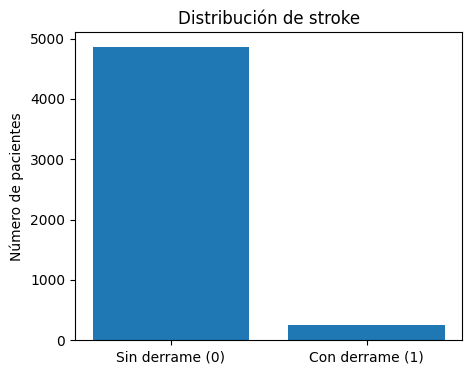

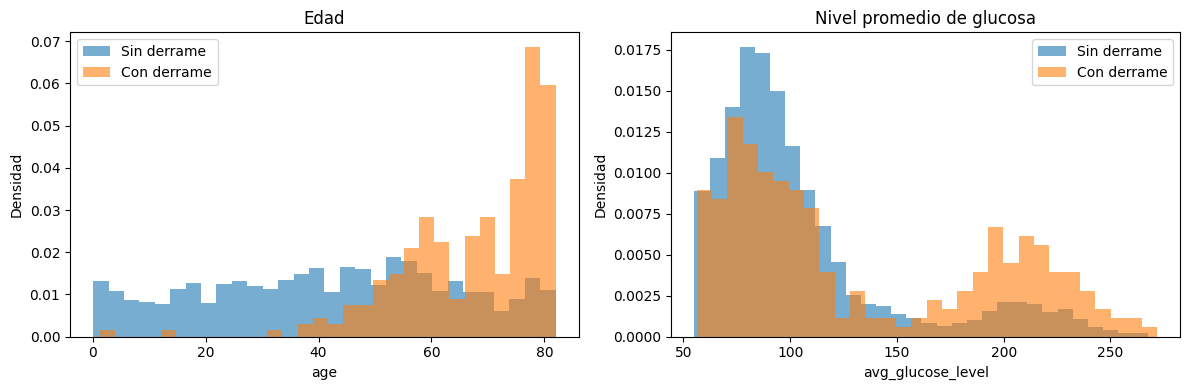

In [50]:
#Distribución de la variable objetivo
conteo = df["stroke"].value_counts()
print(conteo)

plt.figure(figsize=(5, 4))
plt.bar(["Sin derrame (0)", "Con derrame (1)"], [conteo[0], conteo[1]])
plt.title("Distribución de stroke")
plt.ylabel("Número de pacientes")
plt.show()

#Histogramas de age y avg_glucose_level según stroke
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
variables = ["age", "avg_glucose_level"]
titulos = ["Edad", "Nivel promedio de glucosa"]

for ax, col, titulo in zip(axes, variables, titulos):
    ax.hist(df[df["stroke"] == 0][col], bins=30, alpha=0.6, density=True, label="Sin derrame")
    ax.hist(df[df["stroke"] == 1][col], bins=30, alpha=0.6, density=True, label="Con derrame")
    ax.set_title(titulo)
    ax.set_xlabel(col)
    ax.set_ylabel("Densidad")
    ax.legend()

plt.tight_layout()
plt.show()

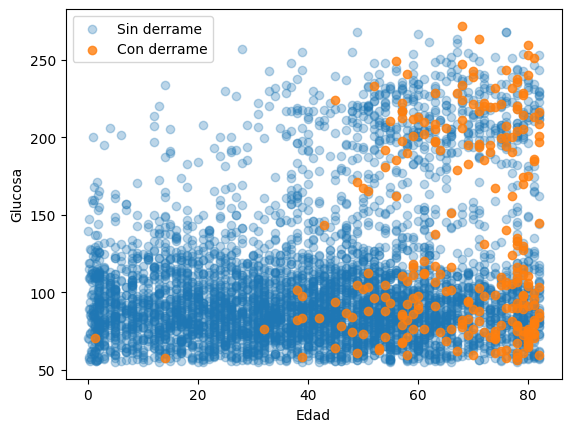

In [51]:
sin = df[df["stroke"] == 0]
con = df[df["stroke"] == 1]

plt.scatter(sin["age"], sin["avg_glucose_level"], alpha=0.3, label="Sin derrame")
plt.scatter(con["age"], con["avg_glucose_level"], alpha=0.8, label="Con derrame")
plt.xlabel("Edad")
plt.ylabel("Glucosa")
plt.legend()
plt.show()